# End-to-end CCF radial velocities — worked example

The `gamse.rv` layer turns an **extracted spectrum** (wavelength + flux) into a
**barycentric radial velocity**, by cross-correlating against a stellar line
mask. It sits on top of GAMSE's reduction (overscan → bias → trace → flat →
extraction).

**Mask:** the official **ESPRESSO G8 CCF mask** (`data/ESPRESSO_G8.fits`, from
[`j-faria/iCCF`](https://github.com/j-faria/iCCF)). The ESPRESSO/HARPS masks are
the community standard (also the basis of NEID-type CCF pipelines); G8 matches our
G6.5 V target. They are in **air** wavelengths — `read_mask` loads the FITS table
directly.

**Data:** the RV standard star **HD 9407** (G6.5 V) observed on three nights with
the Xinglong 2.16 m HRS (2026-10-18, 10-26, 10-27). A standard star has a
constant true RV, so the scatter of the measured RVs *is* the instrument's RV
stability.

> How the spectra were extracted, and caveats (double-fiber flat not applied;
> pixel/aperture offsets), are in [`REDUCTION_NOTES.md`](REDUCTION_NOTES.md).

In [1]:
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# the module this tutorial demonstrates
from gamse.rv import (ccf_rv_batch, read_mask, read_spectrum,
                      compute_ccf, rv_gauss)

%matplotlib inline

## 1. Inputs: extracted spectra, the ESPRESSO mask, target coordinates

Each spectrum is a small FITS file with a `WAVE / FLUX / ERR` table plus the
header keywords the RV step needs (`DATE-OBS`, `EXPTIME`, `RA`, `DEC`). The mask
is the ESPRESSO G8 FITS mask (air wavelengths; `read_mask` keeps 4300–6476 Å and
drops the 6270–6359 Å O₂ band).

In [2]:
DATA  = 'data'
files = sorted(glob.glob(os.path.join(DATA, 'hd9407_*.fits')))
mask  = read_mask(os.path.join(DATA, 'ESPRESSO_G8.fits'))   # ESPRESSO G8, air
coord = SkyCoord('01:34:33.0 +68:56:53', unit=(u.hourangle, u.deg))  # HD 9407

print(len(files), 'spectra,', len(mask[0]), 'ESPRESSO-G8 mask lines')
for f in files:
    print(' ', os.path.basename(f))

7 spectra, 1800 ESPRESSO-G8 mask lines
  hd9407_20261018_050.fits
  hd9407_20261018_051.fits
  hd9407_20261026_062.fits
  hd9407_20261026_063.fits
  hd9407_20261026_064.fits
  hd9407_20261027_043.fits
  hd9407_20261027_044.fits


## 2. Look at one spectrum and its CCF

First the **continuum-normalised flux** of one frame (zoomed to the Mg b region
so the absorption lines are visible), then the **CCF** the ESPRESSO mask produces,
with the Gaussian centroid that defines the radial velocity.

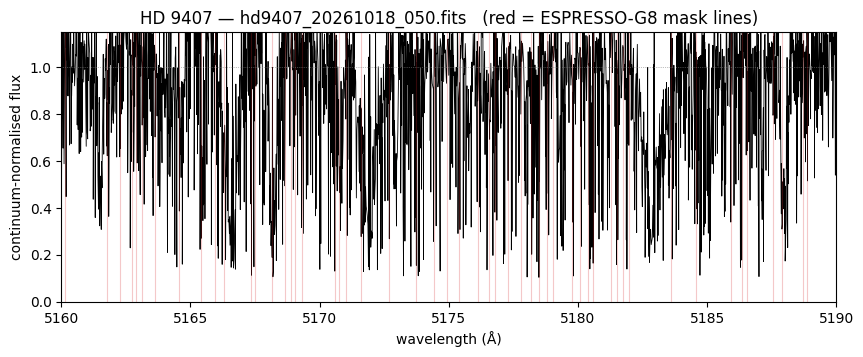

In [3]:
sp = read_spectrum(files[0])
mwl, mwt = mask

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sp['wave'], sp['flux'], lw=0.6, color='k')
for w0 in mwl[(mwl > 5160) & (mwl < 5190)]:
    ax.axvline(w0, color='tab:red', alpha=0.25, lw=0.8)
ax.axhline(1.0, color='gray', lw=0.5, ls=':')
ax.set_xlim(5160, 5190); ax.set_ylim(0.0, 1.15)
ax.set_xlabel('wavelength (Å)'); ax.set_ylabel('continuum-normalised flux')
ax.set_title('HD 9407 — %s   (red = ESPRESSO-G8 mask lines)' % os.path.basename(files[0]))
plt.show()

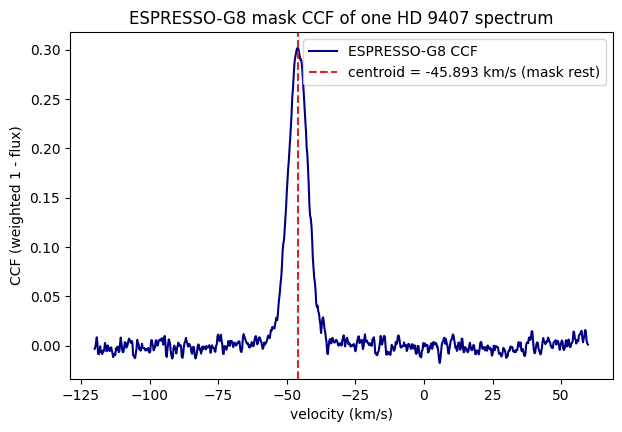

mask-rest RV = -45.893 km/s; add BERV for the barycentric RV (next cell).


In [4]:
vgrid = np.arange(-120.0, 60.0, 0.25)
ccf = compute_ccf(sp['wave'], sp['flux'], mwl, mwt, vgrid)
rv_rest, rv_err = rv_gauss(vgrid, ccf)   # mask-rest centroid (km/s)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(vgrid, ccf, color='navy', lw=1.5, label='ESPRESSO-G8 CCF')
ax.axvline(rv_rest, color='tab:red', ls='--',
           label='centroid = %.3f km/s (mask rest)' % rv_rest)
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel('CCF (weighted 1 - flux)')
ax.set_title('ESPRESSO-G8 mask CCF of one HD 9407 spectrum')
ax.legend(); plt.show()
print('mask-rest RV = %.3f km/s; add BERV for the barycentric RV (next cell).' % rv_rest)

## 3. One call: all spectra → barycentric RVs

`ccf_rv_batch` does the above for every frame and adds the barycentric
correction. Xinglong `DATE-OBS` is Beijing local time, so `utc_offset_hours=8`.
`method='gauss'` = Gaussian centroid of the mask CCF (for broad-lined / fast
rotators / low S/N use `method='chunk'`).

In [5]:
tab = ccf_rv_batch(files, mask, coord=coord, method='gauss', utc_offset_hours=8.0)
tab['rv_ms'] -= np.median(tab['rv_ms'])   # standard star → anomaly ~ 0

print('  file                          BJD_TDB        RV[m/s]   err[m/s]  BERV[km/s]')
for r in tab:
    print('  %-28s %.5f  %+8.1f  %7.1f  %+8.3f'
          % (r['file'], r['bjd'], r['rv_ms'], r['err_ms'], r['berv_kms']))

  file                          BJD_TDB        RV[m/s]   err[m/s]  BERV[km/s]
  hd9407_20261018_050.fits     2461332.24755    +382.6     17.2    +9.174
  hd9407_20261018_051.fits     2461332.24950    +304.7     15.8    +9.172
  hd9407_20261026_062.fits     2461340.10327      +5.7     16.3    +7.115
  hd9407_20261026_063.fits     2461340.10613     -10.3     16.4    +7.112
  hd9407_20261026_064.fits     2461340.10914      -3.5     15.8    +7.109
  hd9407_20261027_043.fits     2461341.37869      +0.0     15.9    +6.592
  hd9407_20261027_044.fits     2461341.38070     -11.4     16.1    +6.592


## 4. Per-night zero-point → the instrument's RV stability

In [6]:
nightkey = np.array([r['file'].split('_')[1] for r in tab])
means = {}
for nk in ['20261018', '20261026', '20261027']:
    m = nightkey == nk
    if m.any():
        means[nk] = np.mean(tab['rv_ms'][m])
        print('  %s : %+8.1f m/s  (scatter %.0f m/s, N=%d)'
              % (nk, means[nk], np.std(tab['rv_ms'][m]), m.sum()))

print('\n  adjacent nights 10-26 vs 10-27 : %+.0f m/s  (rock-stable)'
      % (means['20261027'] - means['20261026']))
print('  ~8-day drift   10-18 vs 10-27 : %+.0f m/s  (tie with standard stars)'
      % (means['20261027'] - means['20261018']))

  20261018 :   +343.6 m/s  (scatter 39 m/s, N=2)
  20261026 :     -2.7 m/s  (scatter 7 m/s, N=3)
  20261027 :     -5.7 m/s  (scatter 6 m/s, N=2)

  adjacent nights 10-26 vs 10-27 : -3 m/s  (rock-stable)
  ~8-day drift   10-18 vs 10-27 : -349 m/s  (tie with standard stars)


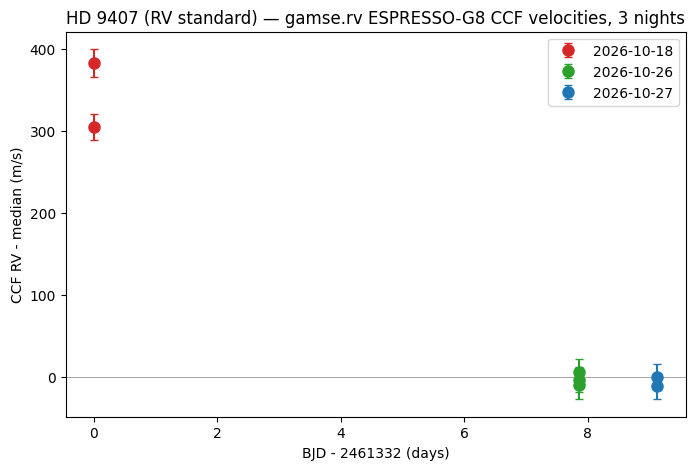

In [7]:
colors = {'20261018': 'tab:red', '20261026': 'tab:green', '20261027': 'tab:blue'}
labels = {'20261018': '2026-10-18', '20261026': '2026-10-26', '20261027': '2026-10-27'}
fig, ax = plt.subplots(figsize=(8, 5))
for nk in colors:
    m = nightkey == nk
    if not m.any():
        continue
    ax.errorbar(tab['bjd'][m] - tab['bjd'].min(), tab['rv_ms'][m], tab['err_ms'][m],
                fmt='o', ms=8, capsize=3, color=colors[nk], label=labels[nk])
ax.axhline(0, color='gray', lw=0.5)
ax.set_xlabel('BJD - %.0f (days)' % tab['bjd'].min())
ax.set_ylabel('CCF RV - median (m/s)')
ax.set_title('HD 9407 (RV standard) — gamse.rv ESPRESSO-G8 CCF velocities, 3 nights')
ax.legend(); plt.show()

**Takeaway:** adjacent nights repeat to ~m/s; there is a few-hundred-m/s common
zero-point drift over ~8 days that must be removed with standard stars before
combining multi-night RVs. The module stops at RV — orbit / Rossiter-McLaughlin
modelling is left to downstream tools.